In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import OrdinalEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report , confusion_matrix , precision_score, recall_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import shap

# Data Cleaning

In [3]:
columns = [
    'checking_account',
    'duration',
    'credit_history',
    'purpose',
    'credit_amount',
    'savings',
    'employment',
    'installment_rate',
    'personal_status_sex',
    'other_debtors',
    'residence_since',
    'property',
    'age',
    'other_installment_plans',
    'housing',
    'existing_credits',
    'job',
    'num_dependents',
    'telephone',
    'foreign_worker',
    'target'
]

df = pd.read_csv(
    '/content/drive/MyDrive/german.data',
    sep=r'\s+',
    header=None,
    names=columns
)

print(df.shape)
df.head()

(1000, 21)


,checking_account,duration,credit_history,purpose,credit_amount,savings,employment,installment_rate,personal_status_sex,other_debtors,...,property,age,other_installment_plans,housing,existing_credits,job,num_dependents,telephone,foreign_worker,target
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2


In [4]:
display(df.info())
print(f"miss value : {df.isnull().sum().sum()}")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   checking_account         1000 non-null   object
 1   duration                 1000 non-null   int64 
 2   credit_history           1000 non-null   object
 3   purpose                  1000 non-null   object
 4   credit_amount            1000 non-null   int64 
 5   savings                  1000 non-null   object
 6   employment               1000 non-null   object
 7   installment_rate         1000 non-null   int64 
 8   personal_status_sex      1000 non-null   object
 9   other_debtors            1000 non-null   object
 10  residence_since          1000 non-null   int64 
 11  property                 1000 non-null   object
 12  age                      1000 non-null   int64 
 13  other_installment_plans  1000 non-null   object
 14  housing                  1000 non-null   

None

miss value : 0


### Data Types and Missing Values

The German Credit dataset contains 1,000 records and 21 columns, including 20 input features and one target variable.

Based on the dataset structure, the features can be divided into two main groups:

**1. Numerical Features:**

These features contain numerical values and represent measurable quantities:

- `duration`
- `credit_amount`
- `installment_rate`
- `residence_since`
- `age`
- `existing_credits`
- `num_dependents`

**2. Categorical Features:**

These features represent groups, categories, or customer characteristics rather than direct numerical values:

- `checking_account`
- `credit_history`
- `purpose`
- `savings`
- `employment`
- `personal_status_sex`
- `other_debtors`
- `property`
- `other_installment_plans`
- `housing`
- `job`
- `telephone`
- `foreign_worker`

The `target` column is also numerical in its current format, with two possible values: 1 for good credit customers and 2 for bad credit customers.

**Missing Values Check:**

After checking the dataset, all 1,000 records have valid values in all 21 columns. There are no missing values in the dataset. Therefore, no missing value handling or imputation is needed at this stage.


Distribution & Outliers

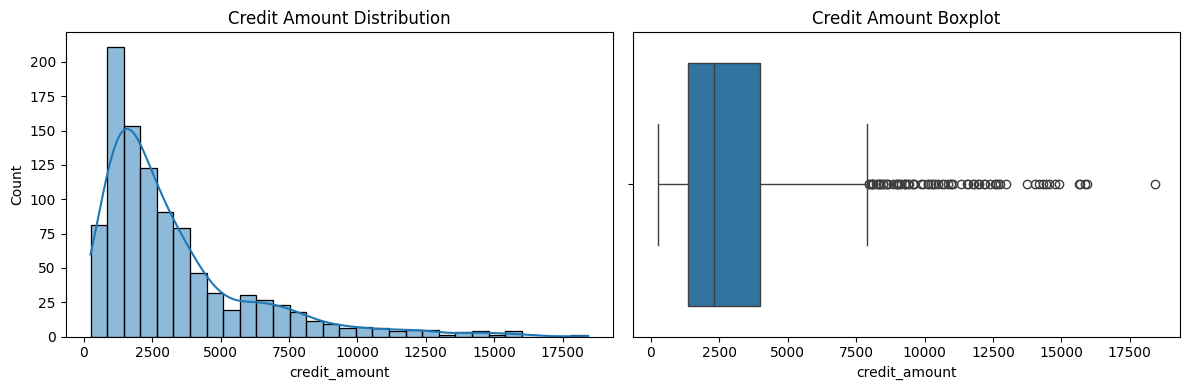

In [5]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.histplot(df['credit_amount'], bins=30, kde=True)
plt.title('Credit Amount Distribution')

plt.subplot(1, 2, 2)
sns.boxplot(x= df['credit_amount'])
plt.title('Credit Amount Boxplot')

plt.tight_layout()
plt.show()

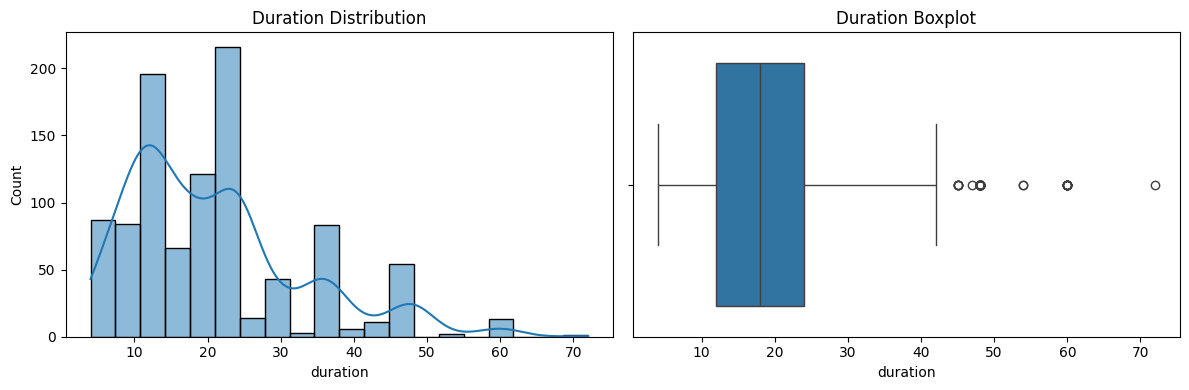

In [6]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.histplot(df['duration'], bins=20, kde=True)
plt.title('Duration Distribution')

plt.subplot(1, 2, 2)
sns.boxplot(x=df['duration'])
plt.title('Duration Boxplot')

plt.tight_layout()
plt.show()

### Distribution and Outlier Analysis

**1. Credit Amount:**

The histogram shows that most customers received loans with amounts between 0 and 5,000 DM. The median credit amount is approximately 2,500 DM. The boxplot also shows several outliers, mainly related to very large loan amounts that are far from the median. The distribution is right-skewed, which means that a small number of customers received much larger loans than most others.

**2. Loan Duration:**

The distribution of loan duration is more spread out, and there is no single interval that clearly contains most of the customers. According to the boxplot, the median loan duration is approximately 18 months. There are also some outliers representing unusually long repayment periods.

**Overall Observation:**

Both credit amount and loan duration show right-skewed distributions. This means that most observations are concentrated around lower values, while a smaller number of observations have much higher values. These outliers may represent real customer records and should not be removed without further investigation.


In [7]:
for col in ['credit_amount', 'duration']:

  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)

  IQR = Q3 - Q1

  lower = Q1 - 1.5 * IQR
  upper = Q3 + 1.5 * IQR

  outliers = df[
    (df[col] < lower) | (df[col] > upper)
  ]

  print(col, 'Outliers:', len(outliers))

credit_amount Outliers: 72
duration Outliers: 70


Association & Correlation

In [8]:
numerical_cols = [
    'duration',
    'credit_amount',
    'installment_rate',
    'residence_since',
    'age',
    'existing_credits',
    'num_dependents',
    'target'
]

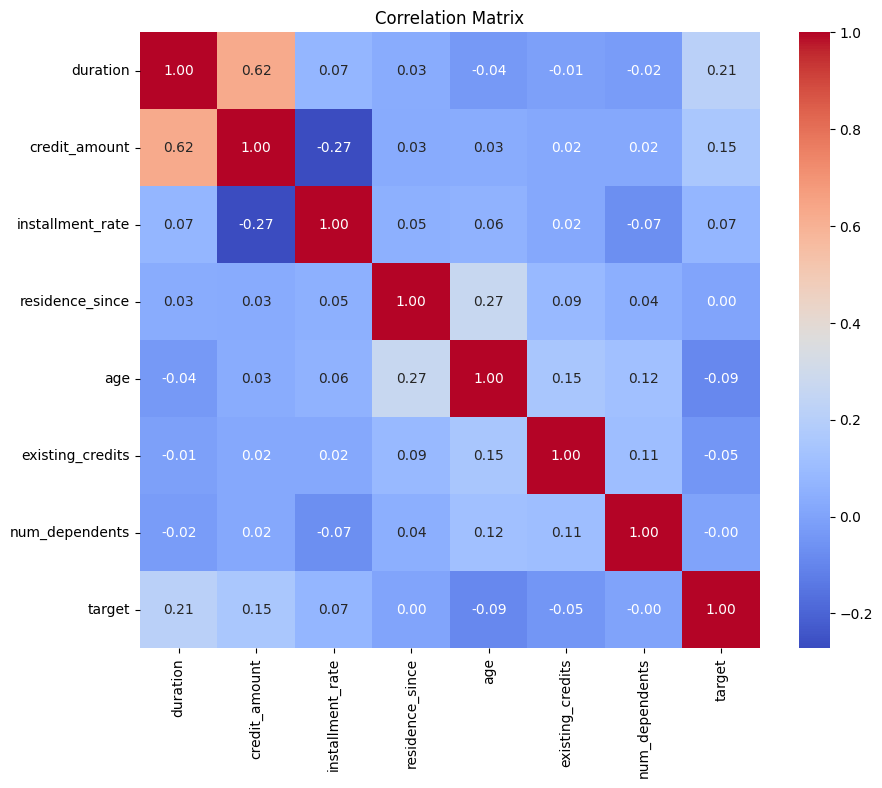

In [9]:
corr_matrix = df[numerical_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix')
plt.show()

In [10]:
account_analysis = pd.crosstab(
    df['checking_account'],
    df['target'],
    normalize='index',

)*100
print(account_analysis)

target                    1          2
checking_account                      
A11               50.729927  49.270073
A12               60.966543  39.033457
A13               77.777778  22.222222
A14               88.324873  11.675127


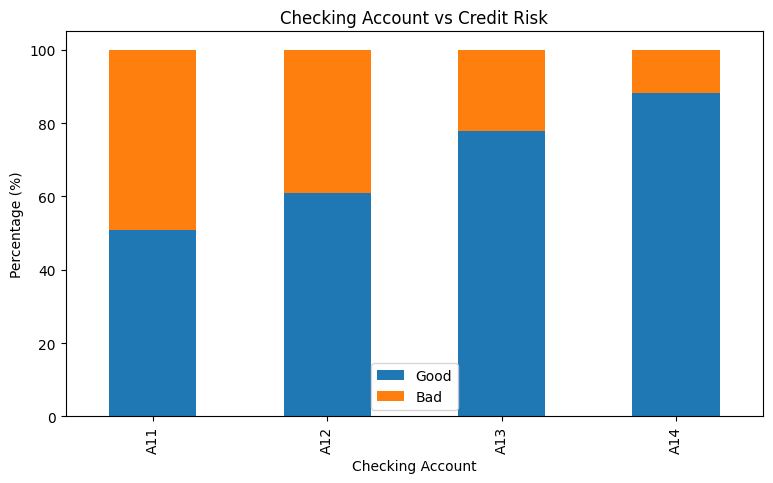

In [11]:
account_analysis.plot(
    kind='bar',
    stacked=True,
    figsize=(9, 5)
)

plt.title('Checking Account vs Credit Risk')
plt.xlabel('Checking Account')
plt.ylabel('Percentage (%)')
plt.legend(['Good', 'Bad'])
plt.show()

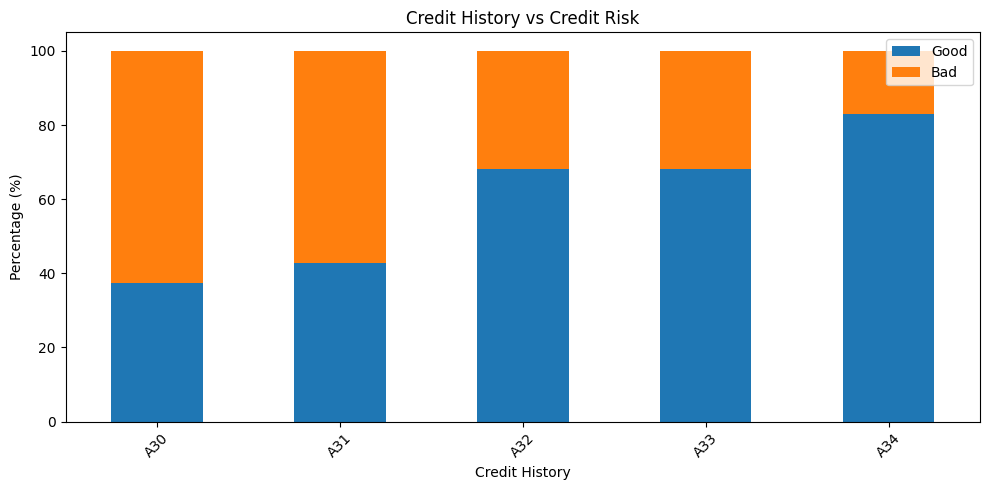

In [12]:
history_analysis = pd.crosstab(
    df['credit_history'],
    df['target'],
    normalize='index'
) * 100


history_analysis.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 5)
)

plt.title('Credit History vs Credit Risk')
plt.xlabel('Credit History')
plt.ylabel('Percentage (%)')
plt.legend(['Good', 'Bad'])
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


In [13]:
history_counts = pd.crosstab(
    df['credit_history'],
    df['target']
)

print(history_counts)

target            1    2
credit_history          
A30              15   25
A31              21   28
A32             361  169
A33              60   28
A34             243   50


In [14]:
print(history_analysis[2])

credit_history
A30    62.500000
A31    57.142857
A32    31.886792
A33    31.818182
A34    17.064846
Name: 2, dtype: float64


### Association and Correlation Analysis

**1. Correlation Analysis**

The correlation matrix shows a moderate positive relationship (0.62) between `duration` and `credit_amount`. This means that customers who receive larger loans usually have longer repayment periods.


**2. Checking Account and Default Risk**

The bar chart shows that customers with higher checking account balances usually have lower default rates. In particular, customers in category A13, who have at least 200 DM in their accounts, have a lower percentage of bad credit cases than customers in the lower-balance categories.

Overall, the results suggest that checking account balance may be an important feature for understanding credit risk.

**3. Credit History and Default Risk**

The results show clear differences in default rates across the five credit history categories. Interestingly, the results are different from what we might expect based on the category descriptions.

A30 has the highest default rate (62.5%), followed by A31 (57.1%). A32 and A33 have similar default rates of about 32%, while A34 has the lowest rate (17.1%).

This result is interesting because A34 represents customers with a critical credit history or other existing credits at different banks. However, this group has the lowest default rate in our dataset.

We should also consider the number of customers in each group. For example, A30 has only 40 customers, while A34 has 293 customers. This means that the results for smaller groups may be more affected by the number of customers.

Overall, credit history is related to default risk in this dataset, but the relationship does not follow a simple order. More analysis is needed to understand this pattern.


**Class Imbalance**

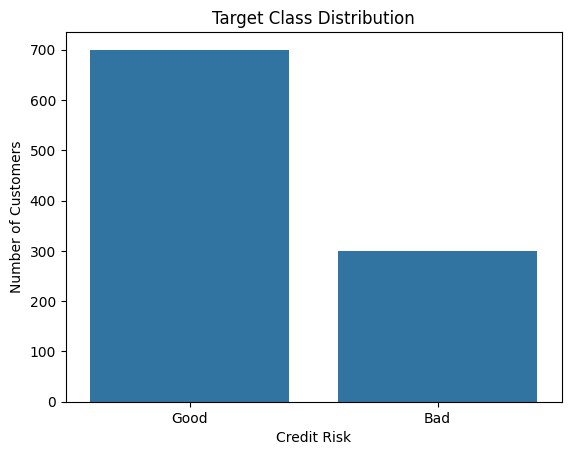


-------------------------------------
target
1    700
2    300
Name: count, dtype: int64


In [15]:
sns.countplot(data=df, x='target')

plt.title('Target Class Distribution')
plt.xlabel('Credit Risk')
plt.ylabel('Number of Customers')
plt.xticks([0, 1], ['Good', 'Bad'])

plt.show()
print('\n-------------------------------------')
print(df['target'].value_counts())

The dataset contains 700 good customers and 300 bad customers. This shows that the dataset is imbalanced because the number of good customers is much higher than the number of bad customers.

This imbalance may cause the machine learning model to be biased toward the majority class (good customers). As a result, the model may not predict bad customers accurately.

Therefore, we should consider using a data balancing technique during the model development process to reduce this problem and improve the model's performance.

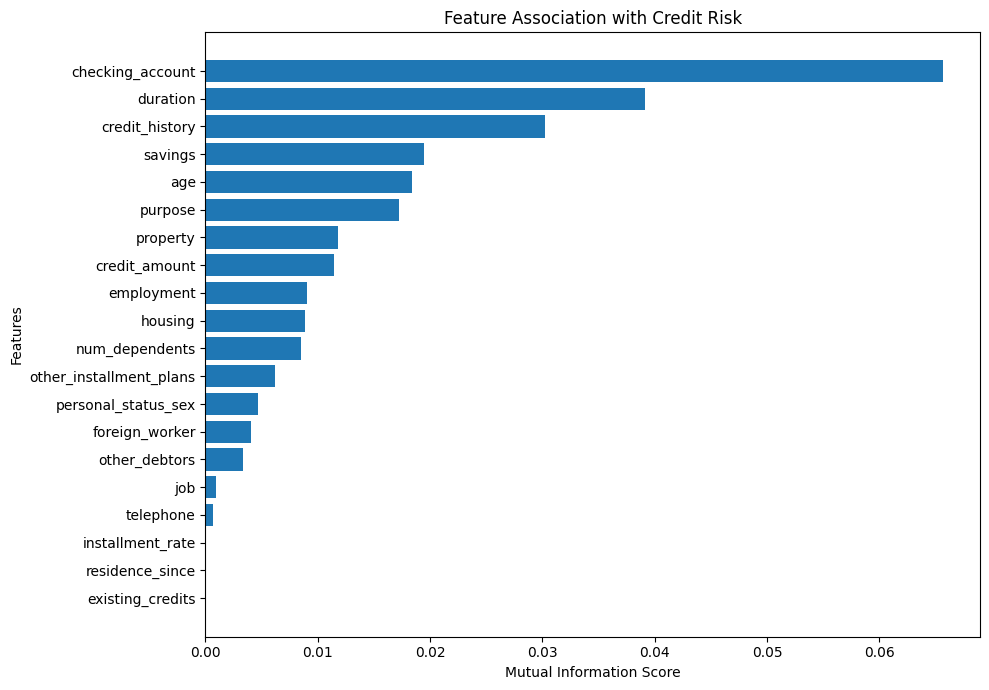

In [16]:
# Separate numerical and categorical features
numerical_cols = [
    'duration', 'credit_amount', 'installment_rate',
    'residence_since', 'age', 'existing_credits',
    'num_dependents'
]

categorical_cols = [
    'checking_account', 'credit_history', 'purpose',
    'savings', 'employment', 'personal_status_sex',
    'other_debtors', 'property', 'other_installment_plans',
    'housing', 'job', 'telephone', 'foreign_worker'
]

# Prepare the features
X = df[numerical_cols + categorical_cols].copy()

# Encode categorical features
for col in categorical_cols:
    X[col] = X[col].astype('category').cat.codes

# Identify categorical columns for Mutual Information
discrete_features = [
    col in categorical_cols for col in X.columns
]

# Calculate Mutual Information
mi_scores = mutual_info_classif(
    X,
    df['target'],
    discrete_features=discrete_features,
    random_state=42
)

# Create a DataFrame
mi_results = pd.DataFrame({
    'Feature': X.columns,
    'MI Score': mi_scores
})

mi_results = mi_results.sort_values(
    by='MI Score',
    ascending=False
)

# Plot the results
plt.figure(figsize=(10, 7))

plt.barh(
    mi_results['Feature'],
    mi_results['MI Score']
)

plt.xlabel('Mutual Information Score')
plt.ylabel('Features')
plt.title('Feature Association with Credit Risk')
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

Finally, we use **Mutual Information (MI)** to examine the relationship between the features and the target variable. This measure shows how much information the value of a feature provides about the target class (good or bad credit).

One advantage of this method is that it can be used to examine both numerical and categorical features.

However, this chart does not prove that a feature will necessarily be important in the final model. It only shows how much information each feature provides about the target variable when considered separately. Therefore, we use it for initial analysis and to identify potentially important features.

# Featur Engineering

In [17]:
X = df.drop('target', axis=1)
y = df['target']

X_train , X_test , y_train , y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
y_train = y_train.map({1: 0, 2: 1})
y_test = y_test.map({1: 0, 2: 1})

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (800, 20)
X_test shape: (200, 20)
y_train shape: (800,)
y_test shape: (200,)


In [18]:
numeric_features = [
    'duration',
    'credit_amount',
    'installment_rate',
    'residence_since',
    'age',
    'existing_credits',
    'num_dependents'
]

# Identify categorical features
categorical_features = [
    col for col in X.columns if col not in numeric_features
]

print("Number of numeric features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))

print("\nCategorical features:")
print(categorical_features)

Number of numeric features: 7
Number of categorical features: 13

Categorical features:
['checking_account', 'credit_history', 'purpose', 'savings', 'employment', 'personal_status_sex', 'other_debtors', 'property', 'other_installment_plans', 'housing', 'job', 'telephone', 'foreign_worker']


In [19]:
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OrdinalEncoder(
            handle_unknown='use_encoded_value',
            unknown_value=-1
        ), categorical_features)
    ],
    remainder='passthrough'
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [20]:
feature_names = preprocessor.get_feature_names_out()

X_train_processed = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_test_processed = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)

print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)

display(X_train_processed.head(10))

Training shape: (800, 20)
Testing shape: (200, 20)


,cat__checking_account,cat__credit_history,cat__purpose,cat__savings,cat__employment,cat__personal_status_sex,cat__other_debtors,cat__property,cat__other_installment_plans,cat__housing,cat__job,cat__telephone,cat__foreign_worker,remainder__duration,remainder__credit_amount,remainder__installment_rate,remainder__residence_since,remainder__age,remainder__existing_credits,remainder__num_dependents
29,0.0,3.0,9.0,0.0,4.0,2.0,0.0,3.0,2.0,1.0,2.0,1.0,0.0,60.0,6836.0,3.0,4.0,63.0,2.0,1.0
535,2.0,4.0,7.0,0.0,1.0,0.0,0.0,2.0,2.0,0.0,2.0,0.0,0.0,21.0,2319.0,2.0,1.0,33.0,1.0,1.0
695,3.0,2.0,1.0,2.0,2.0,2.0,0.0,1.0,2.0,0.0,2.0,0.0,0.0,6.0,1236.0,2.0,4.0,50.0,1.0,1.0
557,3.0,0.0,0.0,4.0,2.0,1.0,0.0,1.0,0.0,1.0,2.0,1.0,0.0,21.0,5003.0,1.0,4.0,29.0,2.0,1.0
836,3.0,2.0,4.0,4.0,2.0,1.0,0.0,2.0,2.0,1.0,2.0,0.0,0.0,12.0,886.0,4.0,2.0,21.0,1.0,1.0
596,0.0,2.0,0.0,0.0,3.0,1.0,0.0,2.0,2.0,0.0,2.0,0.0,0.0,24.0,1442.0,4.0,4.0,23.0,2.0,1.0
165,3.0,2.0,3.0,2.0,2.0,2.0,0.0,2.0,2.0,1.0,2.0,1.0,0.0,6.0,2978.0,1.0,2.0,32.0,1.0,1.0
918,0.0,2.0,3.0,1.0,0.0,0.0,0.0,1.0,2.0,1.0,2.0,0.0,0.0,24.0,2359.0,1.0,1.0,33.0,1.0,1.0
495,0.0,2.0,3.0,4.0,2.0,3.0,0.0,2.0,2.0,1.0,2.0,0.0,0.0,24.0,2996.0,2.0,4.0,20.0,1.0,1.0
824,3.0,4.0,3.0,0.0,1.0,0.0,0.0,2.0,2.0,1.0,3.0,1.0,0.0,18.0,3780.0,3.0,2.0,35.0,2.0,1.0


### Feature Encoding and Scaling

To prepare the dataset for the modeling stage, we used **Ordinal Encoding** to convert the 13 categorical features into numerical values. This method assigns a numerical code to each unique category while preserving the original number of features, avoiding the creation of additional columns.

We also configured the encoder with `handle_unknown='use_encoded_value'` and `unknown_value=-1` to handle previously unseen categories in the test set without generating errors. To prevent data leakage, the encoder was fitted only on the training data and then applied to both training and testing sets.

We did not apply feature scaling to the numerical features because the project primarily uses tree-based models, such as Decision Trees and Random Forests. These models are generally insensitive to the scale of numerical features, as their splitting decisions are based on feature thresholds rather than distances or magnitudes. Therefore, scaling was unnecessary for our selected models.

In [21]:
print(X_train_processed.columns.tolist())

['cat__checking_account', 'cat__credit_history', 'cat__purpose', 'cat__savings', 'cat__employment', 'cat__personal_status_sex', 'cat__other_debtors', 'cat__property', 'cat__other_installment_plans', 'cat__housing', 'cat__job', 'cat__telephone', 'cat__foreign_worker', 'remainder__duration', 'remainder__credit_amount', 'remainder__installment_rate', 'remainder__residence_since', 'remainder__age', 'remainder__existing_credits', 'remainder__num_dependents']


In [22]:
# Create a new categorical feature

X_train['liquidity_profile'] = (
    X_train['checking_account'].astype(str) + '_' +
    X_train['savings'].astype(str)
)

X_test['liquidity_profile'] = (
    X_test['checking_account'].astype(str) + '_' +
    X_test['savings'].astype(str)
)

In [23]:
X_train_processed.head()

,cat__checking_account,cat__credit_history,cat__purpose,cat__savings,cat__employment,cat__personal_status_sex,cat__other_debtors,cat__property,cat__other_installment_plans,cat__housing,cat__job,cat__telephone,cat__foreign_worker,remainder__duration,remainder__credit_amount,remainder__installment_rate,remainder__residence_since,remainder__age,remainder__existing_credits,remainder__num_dependents
29,0.0,3.0,9.0,0.0,4.0,2.0,0.0,3.0,2.0,1.0,2.0,1.0,0.0,60.0,6836.0,3.0,4.0,63.0,2.0,1.0
535,2.0,4.0,7.0,0.0,1.0,0.0,0.0,2.0,2.0,0.0,2.0,0.0,0.0,21.0,2319.0,2.0,1.0,33.0,1.0,1.0
695,3.0,2.0,1.0,2.0,2.0,2.0,0.0,1.0,2.0,0.0,2.0,0.0,0.0,6.0,1236.0,2.0,4.0,50.0,1.0,1.0
557,3.0,0.0,0.0,4.0,2.0,1.0,0.0,1.0,0.0,1.0,2.0,1.0,0.0,21.0,5003.0,1.0,4.0,29.0,2.0,1.0
836,3.0,2.0,4.0,4.0,2.0,1.0,0.0,2.0,2.0,1.0,2.0,0.0,0.0,12.0,886.0,4.0,2.0,21.0,1.0,1.0


In [24]:
liquidity_encoder = OrdinalEncoder(
    handle_unknown='use_encoded_value',
    unknown_value=-1
)

X_train_processed['liquidity_profile'] = (
    liquidity_encoder.fit_transform(
        X_train[['liquidity_profile']]
    ).ravel()
)

X_test_processed['liquidity_profile'] = (
    liquidity_encoder.transform(
        X_test[['liquidity_profile']]
    ).ravel()
)

In [25]:
X_train_processed.head()

,cat__checking_account,cat__credit_history,cat__purpose,cat__savings,cat__employment,cat__personal_status_sex,cat__other_debtors,cat__property,cat__other_installment_plans,cat__housing,...,cat__telephone,cat__foreign_worker,remainder__duration,remainder__credit_amount,remainder__installment_rate,remainder__residence_since,remainder__age,remainder__existing_credits,remainder__num_dependents,liquidity_profile
29,0.0,3.0,9.0,0.0,4.0,2.0,0.0,3.0,2.0,1.0,...,1.0,0.0,60.0,6836.0,3.0,4.0,63.0,2.0,1.0,0.0
535,2.0,4.0,7.0,0.0,1.0,0.0,0.0,2.0,2.0,0.0,...,0.0,0.0,21.0,2319.0,2.0,1.0,33.0,1.0,1.0,10.0
695,3.0,2.0,1.0,2.0,2.0,2.0,0.0,1.0,2.0,0.0,...,0.0,0.0,6.0,1236.0,2.0,4.0,50.0,1.0,1.0,17.0
557,3.0,0.0,0.0,4.0,2.0,1.0,0.0,1.0,0.0,1.0,...,1.0,0.0,21.0,5003.0,1.0,4.0,29.0,2.0,1.0,19.0
836,3.0,2.0,4.0,4.0,2.0,1.0,0.0,2.0,2.0,1.0,...,0.0,0.0,12.0,886.0,4.0,2.0,21.0,1.0,1.0,19.0


In [26]:
features = [
    'cat__checking_account',
    'cat__savings',
    'liquidity_profile'
]

for col in features:
    print(f"\n--- {col} ---")

    bad_rate = (
        pd.DataFrame({
            'feature': X_train_processed[col],
            'target': y_train
        })
        .groupby('feature')['target']
        .agg(['count', 'mean'])
    )

    bad_rate['bad_rate'] = bad_rate['mean'] * 100

    display(
        bad_rate[['count', 'bad_rate']]
        .sort_values('bad_rate', ascending=False)
    )


--- cat__checking_account ---


,count,bad_rate
feature,,
0.0,214,49.065421
1.0,214,38.785047
2.0,49,20.408163
3.0,323,13.312693



--- cat__savings ---


,count,bad_rate
feature,,
1.0,82,35.365854
0.0,474,35.021097
4.0,149,20.805369
2.0,56,17.857143
3.0,39,12.820513



--- liquidity_profile ---


,count,bad_rate
feature,,
6.0,37,54.054054
0.0,167,51.497006
4.0,26,50.000000
1.0,8,50.000000
5.0,120,42.500000
8.0,10,30.000000
11.0,4,25.000000
2.0,8,25.000000
14.0,8,25.000000


We decided to combine checking_account and savings and created a new feature called liquidity_profile by joining the values of these two features. Each unique combination was then converted into a numerical value using OrdinalEncoder.

To evaluate this feature, we compared the bad rate of the original features with the new feature. The results showed a wider range of bad rates for liquidity_profile (9.5%–54.1%), compared to checking_account (13.3%–49.1%) and savings (12.8%–35.4%). This suggests that the new feature may help identify different levels of credit risk.

In [27]:
X_train['credit_profile'] = (
    X_train['credit_history'].astype(str) + '_' +
    X_train['existing_credits'].astype(str)
)

X_test['credit_profile'] = (
    X_test['credit_history'].astype(str) + '_' +
    X_test['existing_credits'].astype(str)
)


In [28]:
print("Credit Profile:")
print(X_train['credit_profile'].nunique())

print(X_train['credit_profile'].value_counts())


Credit Profile:
16
credit_profile
A32_1    376
A34_2    152
A34_1     63
A33_2     48
A32_2     39
A31_1     30
A33_1     24
A30_2     23
A34_3     17
A30_1     10
A31_2      8
A32_3      3
A32_4      2
A30_3      2
A34_4      2
A33_4      1
Name: count, dtype: int64


In [29]:
X_train.head()

,checking_account,duration,credit_history,purpose,credit_amount,savings,employment,installment_rate,personal_status_sex,other_debtors,...,age,other_installment_plans,housing,existing_credits,job,num_dependents,telephone,foreign_worker,liquidity_profile,credit_profile
29,A11,60,A33,A49,6836,A61,A75,3,A93,A101,...,63,A143,A152,2,A173,1,A192,A201,A11_A61,A33_2
535,A13,21,A34,A46,2319,A61,A72,2,A91,A101,...,33,A143,A151,1,A173,1,A191,A201,A13_A61,A34_1
695,A14,6,A32,A41,1236,A63,A73,2,A93,A101,...,50,A143,A151,1,A173,1,A191,A201,A14_A63,A32_1
557,A14,21,A30,A40,5003,A65,A73,1,A92,A101,...,29,A141,A152,2,A173,1,A192,A201,A14_A65,A30_2
836,A14,12,A32,A43,886,A65,A73,4,A92,A101,...,21,A143,A152,1,A173,1,A191,A201,A14_A65,A32_1


In [30]:
features = [
    'credit_profile',
    'credit_history',
    'existing_credits',
]

for col in features:
    print(f"\n--- {col} ---")

    result = pd.DataFrame({
        'feature': X_train[col],
        'target': y_train
    })

    bad_rate = result.groupby('feature')['target'].agg(
        count='count',
        bad_rate='mean'
    )

    bad_rate['bad_rate'] *= 100

    display(
        bad_rate.sort_values(
            'bad_rate',
            ascending=False
        )
    )


--- credit_profile ---


,count,bad_rate
feature,,
A33_4,1,100.000000
A31_2,8,75.000000
A30_2,23,69.565217
A32_3,3,66.666667
A30_1,10,60.000000
A31_1,30,53.333333
A32_4,2,50.000000
A30_3,2,50.000000
A32_2,39,41.025641



--- credit_history ---


,count,bad_rate
feature,,
A30,35,65.714286
A31,38,57.894737
A32,420,32.142857
A33,73,30.136986
A34,234,16.666667



--- existing_credits ---


,count,bad_rate
feature,,
4,5,40.000000
1,503,31.212724
2,270,28.888889
3,22,18.181818


In [31]:
credit_profile = OrdinalEncoder(
    handle_unknown='use_encoded_value',
    unknown_value=-1
)

X_train_processed['credit_profile'] = (
    credit_profile.fit_transform(
        X_train[['credit_profile']]
    ).ravel()
)

X_test_processed['credit_profile'] = (
    credit_profile.transform(
        X_test[['credit_profile']]
    ).ravel()
)

In [32]:
X_train_processed.head()

,cat__checking_account,cat__credit_history,cat__purpose,cat__savings,cat__employment,cat__personal_status_sex,cat__other_debtors,cat__property,cat__other_installment_plans,cat__housing,...,cat__foreign_worker,remainder__duration,remainder__credit_amount,remainder__installment_rate,remainder__residence_since,remainder__age,remainder__existing_credits,remainder__num_dependents,liquidity_profile,credit_profile
29,0.0,3.0,9.0,0.0,4.0,2.0,0.0,3.0,2.0,1.0,...,0.0,60.0,6836.0,3.0,4.0,63.0,2.0,1.0,0.0,10.0
535,2.0,4.0,7.0,0.0,1.0,0.0,0.0,2.0,2.0,0.0,...,0.0,21.0,2319.0,2.0,1.0,33.0,1.0,1.0,10.0,12.0
695,3.0,2.0,1.0,2.0,2.0,2.0,0.0,1.0,2.0,0.0,...,0.0,6.0,1236.0,2.0,4.0,50.0,1.0,1.0,17.0,5.0
557,3.0,0.0,0.0,4.0,2.0,1.0,0.0,1.0,0.0,1.0,...,0.0,21.0,5003.0,1.0,4.0,29.0,2.0,1.0,19.0,1.0
836,3.0,2.0,4.0,4.0,2.0,1.0,0.0,2.0,2.0,1.0,...,0.0,12.0,886.0,4.0,2.0,21.0,1.0,1.0,19.0,5.0


We decided to combine credit_history and existing_credits. By combining these two features, we wanted to find patterns that might not be clear when looking at each feature separately.We compared the Bad Rate of different combinations and found clear differences. For example, A30_2 had a Bad Rate of about 69.6%, while A34_2 had a Bad Rate of about 17.8%.

These results suggest that combining credit history and the number of existing credits may provide useful information about credit risk. However, its final value will be evaluated through model performance.

# Modeling

In [33]:
print("Training data:")
print(X_train_processed.shape)

print("\nTest data:")
print(X_test_processed.shape)

print("\nTraining features:")
print(X_train_processed.columns.tolist())

print("\nTarget distribution:")
print(y_train.value_counts())

Training data:
(800, 22)

Test data:
(200, 22)

Training features:
['cat__checking_account', 'cat__credit_history', 'cat__purpose', 'cat__savings', 'cat__employment', 'cat__personal_status_sex', 'cat__other_debtors', 'cat__property', 'cat__other_installment_plans', 'cat__housing', 'cat__job', 'cat__telephone', 'cat__foreign_worker', 'remainder__duration', 'remainder__credit_amount', 'remainder__installment_rate', 'remainder__residence_since', 'remainder__age', 'remainder__existing_credits', 'remainder__num_dependents', 'liquidity_profile', 'credit_profile']

Target distribution:
target
0    559
1    241
Name: count, dtype: int64


**DecisionTree model**

In [34]:
model1 = DecisionTreeClassifier(
    max_depth=7,
    min_samples_split=10,
    random_state=42
)


In [35]:
model1.fit(X_train_processed, y_train)
y_train_pred = model1.predict(X_train_processed)
y_test_pred = model1.predict(X_test_processed)

print("Training Accuracy:",
      accuracy_score(y_train, y_train_pred))

print("Test Accuracy:",
      accuracy_score(y_test, y_test_pred))

print("\nTest Classification Report:")
print(classification_report(y_test, y_test_pred))

Training Accuracy: 0.86375
Test Accuracy: 0.79

Test Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.86      0.85       141
           1       0.65      0.63      0.64        59

    accuracy                           0.79       200
   macro avg       0.75      0.74      0.75       200
weighted avg       0.79      0.79      0.79       200



First, we developed a basic Decision Tree classifier. We initially used max_depth=5 and min_samples_leaf=10. After evaluating the results, we increased max_depth to 7 to improve the model's performance.

The final model achieved 79% test accuracy. For class 1 (Bad Credit), Precision was 65%, Recall was 63%, and F1-score was 64%.

The results showed that increasing the tree depth improved its ability to identify bad customers.

**RandomForest model**

In [36]:
model2 = RandomForestClassifier(
    n_estimators=200,
    max_depth=7,
    min_samples_leaf=5,
    class_weight={0: 1, 1: 2},
    random_state=42,
    n_jobs=-1
)

In [37]:
model2.fit(X_train_processed, y_train)

y_train_pred_rf = model2.predict(X_train_processed)
y_test_pred_rf = model2.predict(X_test_processed)

print("Train Accuracy:",
      accuracy_score(y_train, y_train_pred_rf))

print("Test Accuracy:",
      accuracy_score(y_test, y_test_pred_rf))

print("\nTest Classification Report:")
print(classification_report(y_test, y_test_pred_rf))


Train Accuracy: 0.82625
Test Accuracy: 0.81

Test Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.84      0.86       141
           1       0.66      0.75      0.70        59

    accuracy                           0.81       200
   macro avg       0.77      0.79      0.78       200
weighted avg       0.82      0.81      0.81       200



Confusion Matrix:
                 Predicted Good (0)  Predicted Bad (1)
Actual Good (0)                 118                 23
Actual Bad (1)                   15                 44


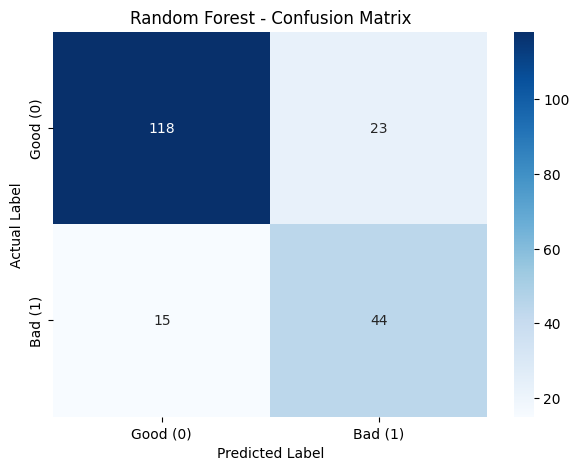

In [38]:
cm = confusion_matrix(y_test, y_test_pred_rf)

print("Confusion Matrix:")
print(pd.DataFrame(
    cm,
    index=['Actual Good (0)', 'Actual Bad (1)'],
    columns=['Predicted Good (0)', 'Predicted Bad (1)']
))

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Good (0)', 'Bad (1)'],
    yticklabels=['Good (0)', 'Bad (1)']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Random Forest - Confusion Matrix')
plt.show()

we developed a Random Forest classifier using n_estimators=200, max_depth=7, and min_samples_leaf=5.

At first, we used equal class weights. However, the model achieved only 42% Recall for class 1. This indicated that it missed many bad customers.

Since our dataset is imbalanced (70% Good and 30% Bad), we increased the weight of class 1 using class_weight={0: 1, 1: 2}. This gave more importance to errors related to bad customers during training.

After changing the weights, Recall for class 1 increased from 42% to 75%, and its F1-score improved from 55% to 70%. Test accuracy also increased from 79.5% to 81%. Although Precision decreased from 78% to 66%, the model identified many more bad customers.

The final Random Forest model achieved 81% test accuracy, with 66% Precision, 75% Recall, and 70% F1-score for class 1.

In [39]:
dt_probs = model1.predict_proba(X_test_processed)[:, 1]
rf_probs = model2.predict_proba(X_test_processed)[:, 1]

results = {
    'Model': ['Decision Tree', 'Random Forest'],
    'ROC-AUC': [
        roc_auc_score(y_test, dt_probs),
        roc_auc_score(y_test, rf_probs)
    ],
    'PR-AUC': [
        average_precision_score(y_test, dt_probs),
        average_precision_score(y_test, rf_probs)
    ]
}

results_df = pd.DataFrame(results)

print(results_df)

           Model   ROC-AUC    PR-AUC
0  Decision Tree  0.731158  0.559182
1  Random Forest  0.834475  0.685371


We also compared the two models using ROC-AUC and PR-AUC. Random Forest achieved higher values for both metrics. This indicates that it has better overall ability to distinguish between good and bad customers. Its higher PR-AUC is also important because our main goal is to identify bad customers, which are the minority class.

Based on these results, Random Forest was selected as the better-performing model for the next stage of evaluation.

In [40]:
X_train_sub , X_val , y_train_sub , y_val = train_test_split(
    X_train_processed,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

In [41]:
model3 = RandomForestClassifier(
    n_estimators=200,
    max_depth=7,
    min_samples_leaf=5,
    class_weight={0: 1, 1: 2},
    random_state= 42,
    n_jobs=-1
)

In [42]:
model3.fit(X_train_sub, y_train_sub)

RandomForestClassifier(class_weight={0: 1, 1: 2}, max_depth=7,
                       min_samples_leaf=5, n_estimators=200, n_jobs=-1,
                       random_state=42)

In [43]:
val_probs = model3.predict_proba(X_val)[:, 1]


thresholds = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]

results = []

for threshold in thresholds:

    y_val_pred = (val_probs >= threshold).astype(int)


    tn, fp, fn, tp = confusion_matrix(
        y_val, y_val_pred, labels=[0, 1]
    ).ravel()


    precision = precision_score(y_val, y_val_pred, zero_division=0)
    recall = recall_score(y_val, y_val_pred)


    cost = 5 * fn + fp

    results.append({
        'Threshold': threshold,
        'Precision': precision,
        'Recall': recall,
        'FP': fp,
        'FN': fn,
        'Cost': cost
    })


results_df = pd.DataFrame(results)

print(results_df.round(3))

   Threshold  Precision  Recall  FP  FN  Cost
0        0.2      0.364   0.917  77   4    97
1        0.3      0.404   0.792  56  10   106
2        0.4      0.440   0.688  42  15   117
3        0.5      0.475   0.583  31  20   131
4        0.6      0.568   0.438  16  27   151
5        0.7      0.538   0.146   6  41   211


In [44]:
final_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=7,
    min_samples_leaf=5,
    class_weight={0: 1, 1: 2},
    random_state=42,
    n_jobs=-1
)


final_model.fit(X_train_processed, y_train)

RandomForestClassifier(class_weight={0: 1, 1: 2}, max_depth=7,
                       min_samples_leaf=5, n_estimators=200, n_jobs=-1,
                       random_state=42)

In [45]:
test_probs = final_model.predict_proba(X_test_processed)[:, 1]
y_test_pred_final = (test_probs >= 0.2).astype(int)

print("Test Accuracy:",
      accuracy_score(y_test, y_test_pred_final))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_final))

cm = confusion_matrix(
    y_test,
    y_test_pred_final,
    labels=[0, 1]
)

print("\nConfusion Matrix:")
print(cm)

tn, fp, fn, tp = cm.ravel()

cost = 5 * fn + fp

print("\nTotal Error Cost:", cost)

Test Accuracy: 0.525

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.33      0.50       141
           1       0.38      0.98      0.55        59

    accuracy                           0.53       200
   macro avg       0.68      0.66      0.52       200
weighted avg       0.80      0.53      0.51       200


Confusion Matrix:
[[47 94]
 [ 1 58]]

Total Error Cost: 99


Next, we created a model with the same parameters and tested different decision thresholds, from 0.2 to 0.7. At each threshold, we calculated Precision, Recall, F1-score, and Accuracy. We also calculated the bank's total loss, considering that incorrectly approving a bad customer (False Negative) causes five times more loss than incorrectly rejecting a good customer (False Positive).

Based on the results, a threshold of 0.2 resulted in the lowest total loss for the bank. However, it also classified many good customers as bad, making the model more strict when approving loans.

**XAI**

In [46]:
explainer = shap.TreeExplainer(final_model)
shap_values = explainer(X_test_processed)
print(shap_values.values.shape)

(200, 22, 2)


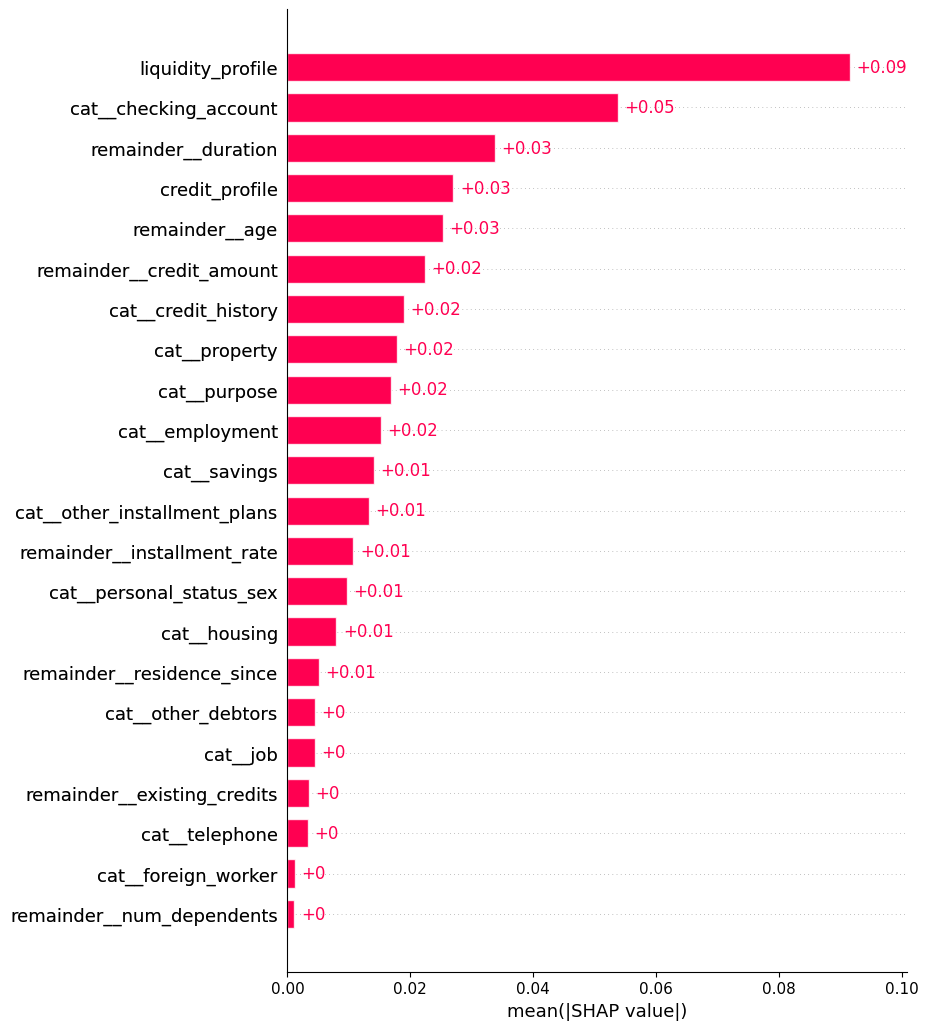

In [47]:
shap.plots.bar(shap_values[:, :, 1], max_display=22)

The SHAP Bar Plot shows that `liquidity_profile` is the most important feature, followed by `checking_account`. Other important features include `duration`, `credit_profile`, and `age`. In contrast, features such as `num_dependents`, `foreign_worker`, and `telephone` have very little influence on the model's predictions. These values show the average importance of each feature, but they do not indicate whether a feature increases or decreases the risk of default.

In [48]:
bad_customers = final_model.predict_proba(X_test_processed)[:, 1]
test_predictions = (bad_customers >= 0.2).astype(int)

selected_indices = np.where(
    (y_test.to_numpy() == 1) & (test_predictions == 1)
)[0]

print("Number of correctly identified bad customers:", len(selected_indices))

Number of correctly identified bad customers: 58


Predicted probability: 0.6694606151360459


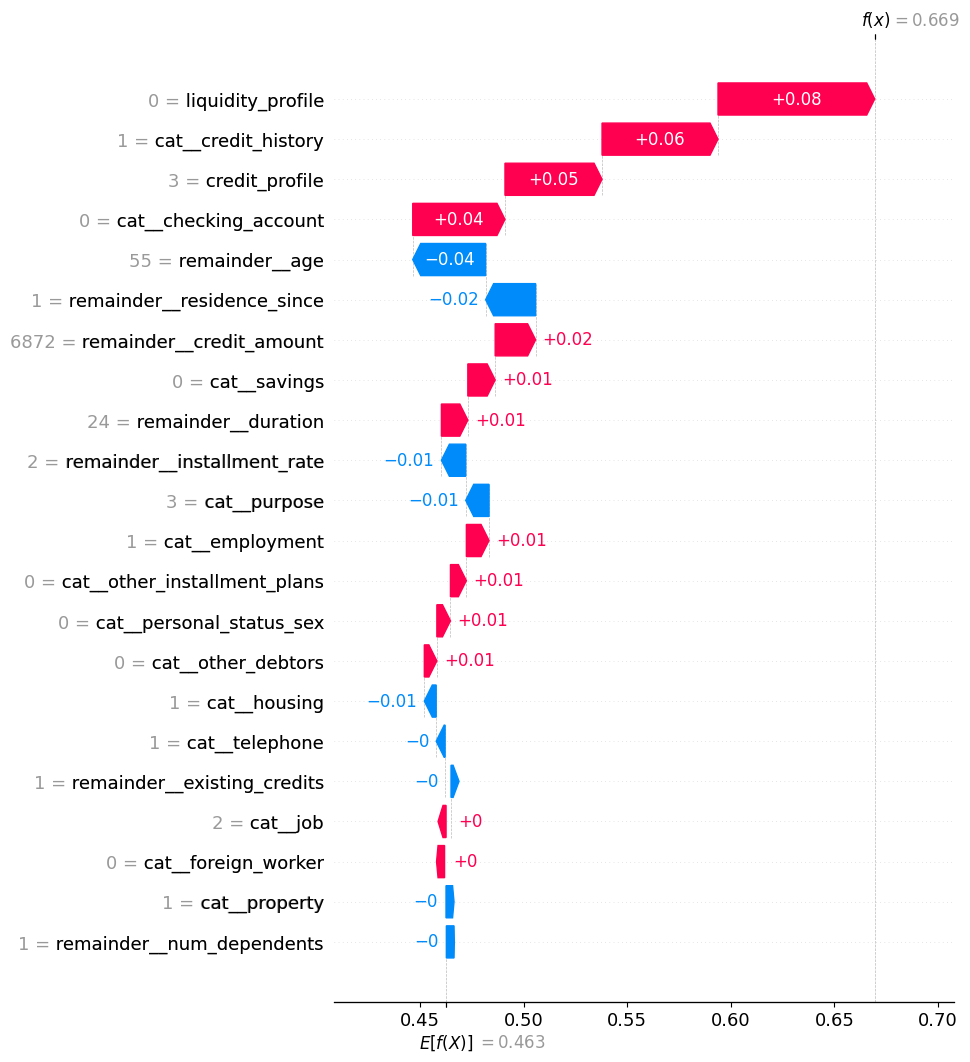

In [49]:
sample_idx = selected_indices[10]

print("Predicted probability:", bad_customers[sample_idx])

shap.plots.waterfall(
    shap_values[sample_idx, :, 1],
    max_display=22
)

Predicted probability: 0.056320439416749496


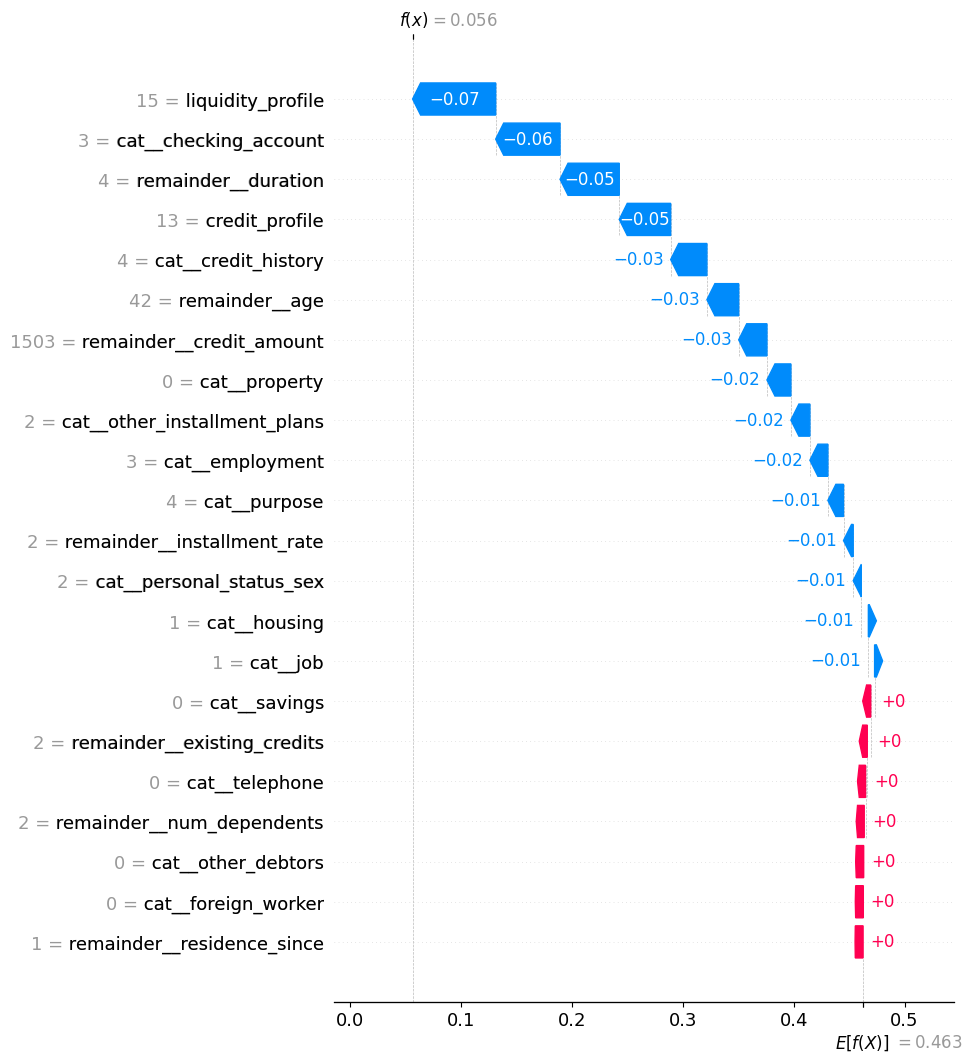

In [50]:
good_customers_indices = np.where(
    (y_test.to_numpy() == 0) & (test_predictions == 0)
)[0]

good_sample_idx = good_customers_indices[
    np.argmin(bad_customers[good_customers_indices])
]

print("Predicted probability:", bad_customers[good_sample_idx])

# Display the SHAP Waterfall Plot
shap.plots.waterfall(
    shap_values[good_sample_idx, :, 1],
    max_display=22
)

The Waterfall Plot explains the prediction for one correctly identified bad customer. The model's output increased from the base value of 0.463 to 0.669. The most important features that increased the predicted risk were `liquidity_profile`, `credit_history`, `credit_profile`, and `checking_account`. On the other hand, features such as `age` and `residence_since` reduced the predicted risk. Since the final output was higher than the decision threshold of 0.2, the model classified this customer as bad. This analysis shows how different features influenced the model's prediction for this specific customer.

# Causality vs Correlation

The results of the SHAP Bar Plot showed that `liquidity_profile` was the most important feature in the model, with an average SHAP value of about 0.09. The next important features were `checking_account`, `duration`, `credit_profile`, and `age`. These results show that the customer's financial situation and credit history play an important role in predicting the risk of default.

Next, we used the SHAP Waterfall Plot to analyze one bad customer who was correctly identified by the model. The model's output increased from the base value of 0.463 to 0.669. The main features that increased the model's output were `liquidity_profile` (+0.08), `credit_history` (+0.06), `credit_profile` (+0.05), and `checking_account` (+0.04). On the other hand, features such as `age` and `residence_since` reduced the model's output.

Based on the model's results, we can divide the features into two groups according to whether the bank can influence them.

The first group includes features that the bank cannot directly change, such as `age`, `credit_history`, and `residence_since`. These features describe the customer's personal information and past records. The bank can use them to evaluate credit risk, but it cannot change them.

The second group includes features that the bank can influence through its lending policies. For example, the bank can choose a suitable loan amount (`credit_amount`) based on the customer's financial situation and ability to repay. It can also adjust the loan duration (`duration`) and installment rate (`installment_rate`) to make repayments more affordable. In addition, checking the customer's financial situation can help the bank better understand their ability to repay the loan and offer suitable financial solutions.

For example, if a customer requests a large loan and the model predicts a high risk of default, the bank can consider reducing the loan amount or changing the repayment conditions instead of rejecting the application completely.